# Demand forecasting for Monash Rideshare hubs

**Question.** How many ride requests will each approved pickup hub get in a given time slot?
The answer feeds the *Demand zones* card in the app (Request a ride / Offer a ride), so a driver can see
where passengers are **expected** to need rides, not only where they asked in the past.

**Data.** The app has no real usage yet (cold start), so the history is the app's own **synthetic** demand
history (`core/demand/SyntheticDemand.kt`): 75 days, 30 hubs, about 2,500 requests, exported by
`DemandHistoryExport`. It is never presented as real student usage. Because the generator's rules are known,
this notebook can also check whether a model *recovers* them - something real data cannot offer.

**Method.**
1. Turn events into an hourly panel (hub x date x hour, zeros included).
2. Split by **time**: first 60 days to train, last 15 days to test (no future data leaks into training).
3. Baselines a model must beat.
4. Poisson regression (counts) and a gradient-boosted tree with a Poisson loss.
5. Evaluate per hour and at the level the app shows (hub x time-of-day block), including top-3 accuracy.
6. Refit the best model on all data and export the forecast the app reads (`demand_forecast.json`).

In [1]:
import json
import os
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")             # quiets a harmless joblib core-count warning on Windows
warnings.filterwarnings("ignore", message="An input array is constant")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

DATA = Path("data")
FIGURES = Path("figures"); FIGURES.mkdir(exist_ok=True)
APP_FORECAST = Path("../app/src/main/resources/demand_forecast.json")
SEED = 7
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

events = pd.read_csv(DATA / "demand_events.csv", parse_dates=["local_time", "date"])
hubs = pd.read_csv(DATA / "hubs.csv")
print(f"{len(events):,} requests at {events.hub.nunique()} hubs, {events.date.min():%d %b} - {events.date.max():%d %b %Y}")
events.head()

2,516 requests at 30 hubs, 18 Jul - 30 Sep 2026


,hub,local_time,date,hour,day_of_week,weekend,weight
0,Glen Waverley Station,2026-07-18T09:07:31,2026-07-18,9,6,True,2.0
1,Footscray Station,2026-07-18T09:10:36,2026-07-18,9,6,True,1.0
2,Oakleigh Station,2026-07-18T09:16:17,2026-07-18,9,6,True,1.0
3,Malvern Central,2026-07-18T10:16:35,2026-07-18,10,6,True,1.0
4,Caulfield Station,2026-07-18T10:22:44,2026-07-18,10,6,True,1.0


## 1. Hourly panel
Every hub, every date, every hour - including hours with **no** requests. A count model has to learn the zeros too.

In [2]:
dates = pd.date_range(events.date.min(), events.date.max(), freq="D")
panel = pd.MultiIndex.from_product([hubs.hub, dates, range(24)], names=["hub", "date", "hour"]).to_frame(index=False)
counts = events.groupby(["hub", "date", "hour"]).size().rename("requests")
panel = panel.join(counts, on=["hub", "date", "hour"]).fillna({"requests": 0})
panel["requests"] = panel.requests.astype(int)
panel["day_of_week"] = panel.date.dt.dayofweek + 1          # 1 = Monday, same as java.time
panel["weekend"] = panel.day_of_week >= 6
panel = panel.merge(hubs[["hub", "role", "cluster_factor"]], on="hub")

def block_of(hour):                                          # DemandPeriod's blocks (DemandModels.kt)
    if 5 <= hour < 10: return "MORNING"
    if 10 <= hour < 15: return "MIDDAY"
    if 15 <= hour < 19: return "AFTERNOON"
    return "EVENING"
panel["block"] = panel.hour.map(block_of)
print(f"{len(panel):,} hub-hours, {(panel.requests == 0).mean():.1%} of them with no request")
panel.describe(include="all").T[["count", "mean", "std", "min", "max"]].dropna()

54,000 hub-hours, 95.7% of them with no request


,count,mean,std,min,max
hour,54000.0,11.5,6.922251,0.0,23.0
requests,54000.0,0.046593,0.227255,0.0,4.0
day_of_week,54000.0,3.986667,2.023174,1.0,7.0
cluster_factor,54000.0,0.656667,0.265437,0.3,1.0


## 2. What the history looks like

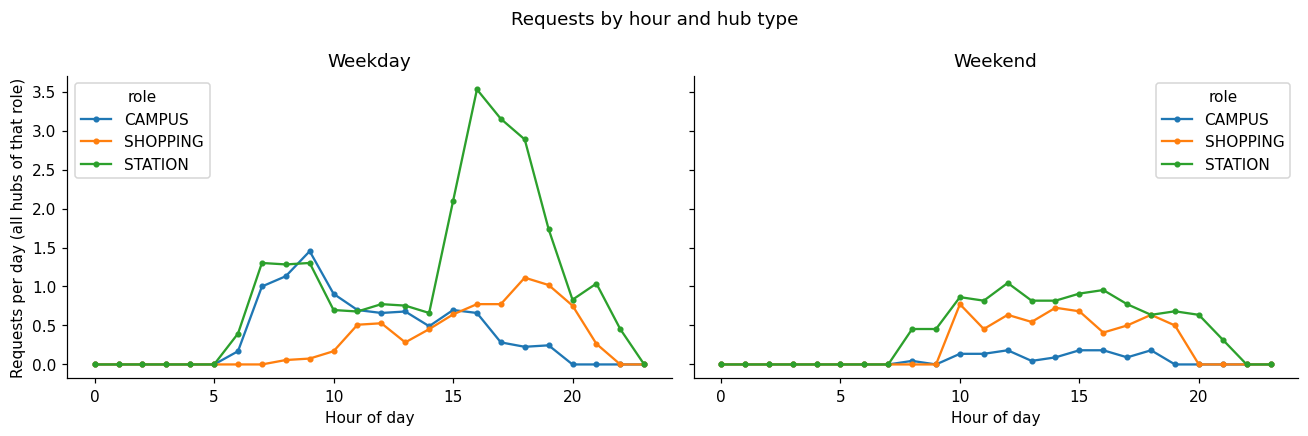

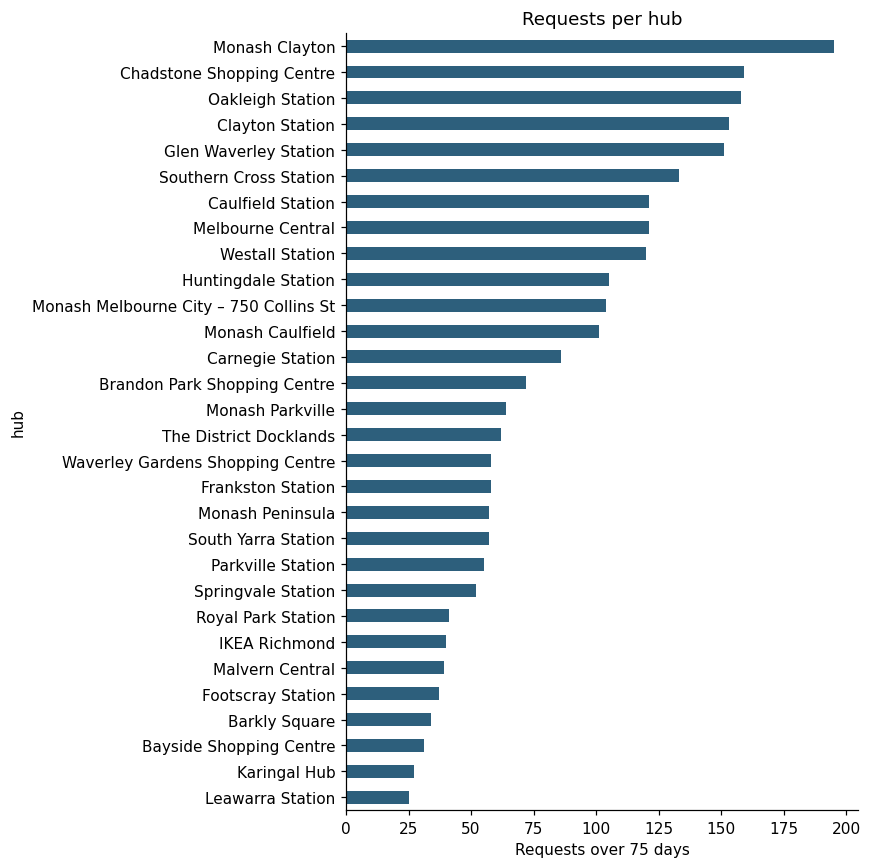

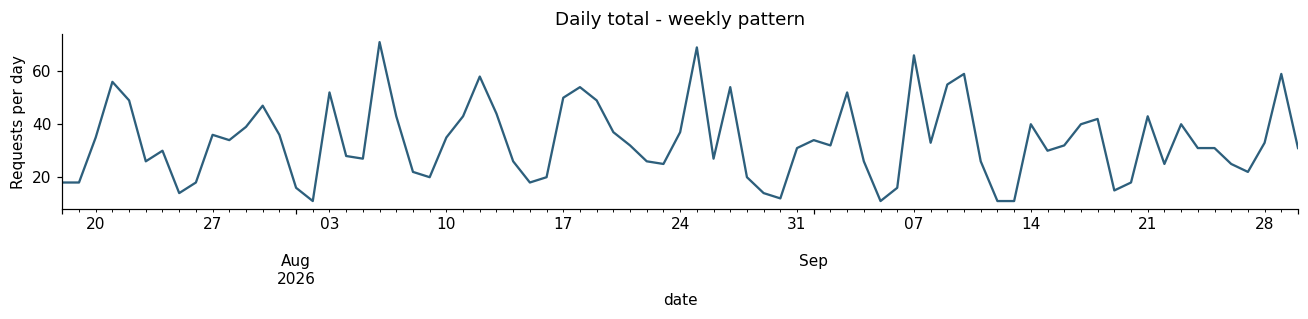

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, weekend in zip(axes, [False, True]):
    days = panel[panel.weekend == weekend].date.nunique()
    profile = panel[panel.weekend == weekend].groupby(["hour", "role"]).requests.sum().unstack() / days
    profile.plot(ax=ax, marker="o", ms=3)
    ax.set_title("Weekend" if weekend else "Weekday"); ax.set_xlabel("Hour of day"); ax.set_ylabel("Requests per day (all hubs of that role)")
fig.suptitle("Requests by hour and hub type"); fig.tight_layout(); fig.savefig(FIGURES / "hourly_profile.png")
plt.show()

top = panel.groupby("hub").requests.sum().sort_values()
ax = top.plot.barh(figsize=(8, 8), color="#2d5f7c"); ax.set_xlabel("Requests over 75 days"); ax.set_title("Requests per hub")
plt.tight_layout(); plt.savefig(FIGURES / "requests_per_hub.png"); plt.show()

daily = panel.groupby("date").requests.sum()
ax = daily.plot(figsize=(12, 3), color="#2d5f7c"); ax.set_ylabel("Requests per day"); ax.set_title("Daily total - weekly pattern")
plt.tight_layout(); plt.savefig(FIGURES / "daily_total.png"); plt.show()

## 3. Train / test split by time
Training is the first 60 days, testing the last 15 - the model is always predicting days it has not seen, as it would in the app.

In [4]:
split = dates[-15]
train, test = panel[panel.date < split].copy(), panel[panel.date >= split].copy()
print(f"train {train.date.min():%d %b} - {train.date.max():%d %b} ({train.date.nunique()} days, {train.requests.sum():,} requests)")
print(f"test  {test.date.min():%d %b} - {test.date.max():%d %b} ({test.date.nunique()} days, {test.requests.sum():,} requests)")

train 18 Jul - 15 Sep (60 days, 2,029 requests)
test  16 Sep - 30 Sep (15 days, 487 requests)


## 4. Baselines
* **Last week repeated** - the same hub and hour, from the last training week with the same weekday.
* **Mean by hub, weekday, hour** - the historical average for that exact slot.
* **Mean by hub, weekday/weekend, hour** - pooled over all weekdays, so each slot has more data.

In [5]:
last_week = train[train.date >= split - pd.Timedelta(days=7)].set_index(["hub", "day_of_week", "hour"]).requests
test["last_week"] = test.set_index(["hub", "day_of_week", "hour"]).index.map(last_week).astype(float)
test["mean_dow"] = test.set_index(["hub", "day_of_week", "hour"]).index.map(train.groupby(["hub", "day_of_week", "hour"]).requests.mean())
test["mean_weekend"] = test.set_index(["hub", "weekend", "hour"]).index.map(train.groupby(["hub", "weekend", "hour"]).requests.mean())

## 5. Models
**Poisson regression.** Requests per hour are counts, so the textbook model is a Poisson GLM with a log link:
`log E[requests] = hub + (hub type x weekday/weekend x hour) + day of week`. Effects multiply, which is easy to
explain ("Tuesday has x1.1 the requests of Friday").

**Gradient-boosted trees (Poisson loss).** A non-linear model on the same information, to check whether a
flexible model finds structure the GLM misses.

In [6]:
def design(frame):
    out = frame[["hub", "role", "hour", "day_of_week", "weekend", "cluster_factor"]].copy()
    out["role_slot"] = out.role + "|" + np.where(out.weekend, "weekend", "weekday") + "|" + out.hour.astype(str)
    return out

glm = make_pipeline(
    ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), ["hub", "role_slot", "day_of_week"])]),
    PoissonRegressor(alpha=1e-4, max_iter=3000),
)
glm.fit(design(train), train.requests)
test["poisson_glm"] = glm.predict(design(test))

tree_features = ["hub_code", "role_code", "hour", "day_of_week", "weekend", "cluster_factor"]
def tree_design(frame):
    out = design(frame)
    out["hub_code"] = pd.Categorical(out.hub, categories=hubs.hub).codes
    out["role_code"] = pd.Categorical(out.role, categories=sorted(hubs.role.unique())).codes
    out["weekend"] = out.weekend.astype(int)
    return out[tree_features]

gbt = HistGradientBoostingRegressor(loss="poisson", learning_rate=0.05, max_iter=400, max_leaf_nodes=31,
                                    categorical_features=[0, 1], random_state=SEED)
gbt.fit(tree_design(train), train.requests)
test["boosted_trees"] = gbt.predict(tree_design(test))

## 6. Evaluation per hub-hour (test days only)

In [7]:
methods = {
    "Last week repeated": "last_week",
    "Mean by hub, weekday, hour": "mean_dow",
    "Mean by hub, weekday/weekend, hour": "mean_weekend",
    "Poisson regression": "poisson_glm",
    "Boosted trees (Poisson)": "boosted_trees",
}
def scores(actual, predicted):
    predicted = np.clip(predicted, 1e-6, None)               # the deviance needs a positive prediction
    return {"MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "Poisson deviance": mean_poisson_deviance(actual, predicted)}
hourly = pd.DataFrame({name: scores(test.requests, test[col]) for name, col in methods.items()}).T
hourly.style.format("{:.4f}").highlight_min(color="#d7ead9")

,MAE,RMSE,Poisson deviance
Last week repeated,0.0796,0.2969,1.0519
"Mean by hub, weekday, hour",0.0805,0.2228,0.5714
"Mean by hub, weekday/weekend, hour",0.0808,0.2134,0.2952
Poisson regression,0.0822,0.2120,0.2233
Boosted trees (Poisson),0.0814,0.2120,0.2204


**Reading this table.** 95.7% of hub-hours have no request, so **MAE rewards predicting almost zero** and barely separates
the methods. For counts the proper score is the **Poisson deviance** (lower is better): it judges the whole predicted rate,
not just how close it is to zero. On deviance both models clearly beat every baseline - the per-slot averages have only a
handful of observations each and overfit, while the models pool information across hubs, hours and days.

## 7. Evaluation at the level the app shows
The card shows one time-of-day block (e.g. *weekday afternoon*), so what matters is requests per **hub x date x block**,
and whether the model picks the right **busiest 3 hubs**.

In [8]:
block_level = test.groupby(["date", "block", "hub"])[["requests", *methods.values()]].sum().reset_index()
block_scores = pd.DataFrame({name: scores(block_level.requests, block_level[col]) for name, col in methods.items()}).T

def top3_hit_rate(column):
    hits = []
    for _, slot in block_level.groupby(["date", "block"]):
        if slot.requests.sum() == 0: continue
        actual = set(slot.nlargest(3, "requests").hub)
        predicted = set(slot.nlargest(3, column).hub)
        hits.append(len(actual & predicted) / 3)
    return np.mean(hits)
block_scores["Top-3 hubs correct"] = [top3_hit_rate(col) for col in methods.values()]
block_scores["Rank correlation"] = [
    block_level.groupby(["date", "block"]).apply(lambda s: s.requests.corr(s[col], method="spearman"), include_groups=False).mean()
    for col in methods.values()]
block_scores.style.format({"MAE": "{:.3f}", "RMSE": "{:.3f}", "Poisson deviance": "{:.3f}",
                           "Top-3 hubs correct": "{:.1%}", "Rank correlation": "{:.3f}"}).highlight_min(
    subset=["MAE", "RMSE", "Poisson deviance"], color="#d7ead9").highlight_max(subset=["Top-3 hubs correct", "Rank correlation"], color="#d7ead9")

,MAE,RMSE,Poisson deviance,Top-3 hubs correct,Rank correlation
Last week repeated,0.376,0.742,4.430,21.8%,0.173
"Mean by hub, weekday, hour",0.347,0.557,1.137,27.0%,0.279
"Mean by hub, weekday/weekend, hour",0.346,0.533,0.695,34.5%,0.317
Poisson regression,0.360,0.538,0.687,32.8%,0.328
Boosted trees (Poisson),0.352,0.536,0.677,33.3%,0.330


One block on one day holds about 0.3 requests per hub, so the *actual* top 3 of a single slot is often a tie decided by chance -
no method can score well there. The card does not show one day either: it shows the **typical** demand for a time bucket.
So the fair app-level test is: over the 15 test days, average requests per day for each hub in each of the 8 buckets, and
compare that with the prediction.

In [9]:
days_of_kind = test.groupby("weekend").date.nunique()        # weekday and weekend days in the test fortnight
period_level = test.groupby(["weekend", "block", "hub"])[["requests", *methods.values()]].sum().div(days_of_kind, level="weekend", axis=0)
period_level = period_level.reset_index()

def period_scores(column):
    top3, rank = [], []
    for _, bucket in period_level.groupby(["weekend", "block"]):
        top3.append(len(set(bucket.nlargest(3, "requests").hub) & set(bucket.nlargest(3, column).hub)) / 3)
        rank.append(bucket.requests.corr(bucket[column], method="spearman"))
    return {"MAE (requests/day)": mean_absolute_error(period_level.requests, period_level[column]),
            "Top-3 hubs correct": np.mean(top3), "Rank correlation": np.nanmean(rank)}
period_scores_table = pd.DataFrame({name: period_scores(col) for name, col in methods.items()}).T
period_scores_table.style.format({"MAE (requests/day)": "{:.3f}", "Top-3 hubs correct": "{:.1%}", "Rank correlation": "{:.3f}"}).highlight_min(
    subset=["MAE (requests/day)"], color="#d7ead9").highlight_max(subset=["Top-3 hubs correct", "Rank correlation"], color="#d7ead9")

,MAE (requests/day),Top-3 hubs correct,Rank correlation
Last week repeated,0.204,29.2%,0.318
"Mean by hub, weekday, hour",0.141,58.3%,0.516
"Mean by hub, weekday/weekend, hour",0.139,62.5%,0.523
Poisson regression,0.152,54.2%,0.577
Boosted trees (Poisson),0.142,54.2%,0.582


In [10]:
baselines = [m for m in methods if m not in ("Poisson regression", "Boosted trees (Poisson)")]
best = hourly["Poisson deviance"].idxmin()
best_baseline = hourly.loc[baselines, "Poisson deviance"].idxmin()
gain = 1 - hourly.loc[best, "Poisson deviance"] / hourly.loc[best_baseline, "Poisson deviance"]
print(f"Best model by Poisson deviance: {best}")
print(f"Deviance vs best baseline ({best_baseline}): {gain:.1%} lower")
print(f"Typical-demand level: top-3 hubs correct {period_scores_table.loc[best, 'Top-3 hubs correct']:.0%}, "
      f"rank correlation {period_scores_table.loc[best, 'Rank correlation']:.2f} "
      f"(best baseline {period_scores_table.loc[best_baseline, 'Top-3 hubs correct']:.0%}, {period_scores_table.loc[best_baseline, 'Rank correlation']:.2f})")

Best model by Poisson deviance: Boosted trees (Poisson)
Deviance vs best baseline (Mean by hub, weekday/weekend, hour): 25.3% lower
Typical-demand level: top-3 hubs correct 54%, rank correlation 0.58 (best baseline 62%, 0.52)


### Result in one paragraph
Both models beat every baseline on **Poisson deviance** (about a quarter lower than the best baseline) and order the 30 hubs
best (**rank correlation**). On picking the exact **top 3** hubs per bucket, the pooled historical mean is as good or slightly
better - but that score rests on only 8 buckets x 3 picks over 15 test days, so one pick moves it by about 4 points.
The honest conclusion: the model is the better *estimate of demand*, with little room left to beat a well-chosen average on
data this sparse. That is expected - the history is generated from a fixed hourly pattern, which a good average also captures.
The model's advantages grow with real data: it extrapolates to slots with little history (new hubs, rare hours) and can take
new signals (weather, exam weeks) that an average cannot.

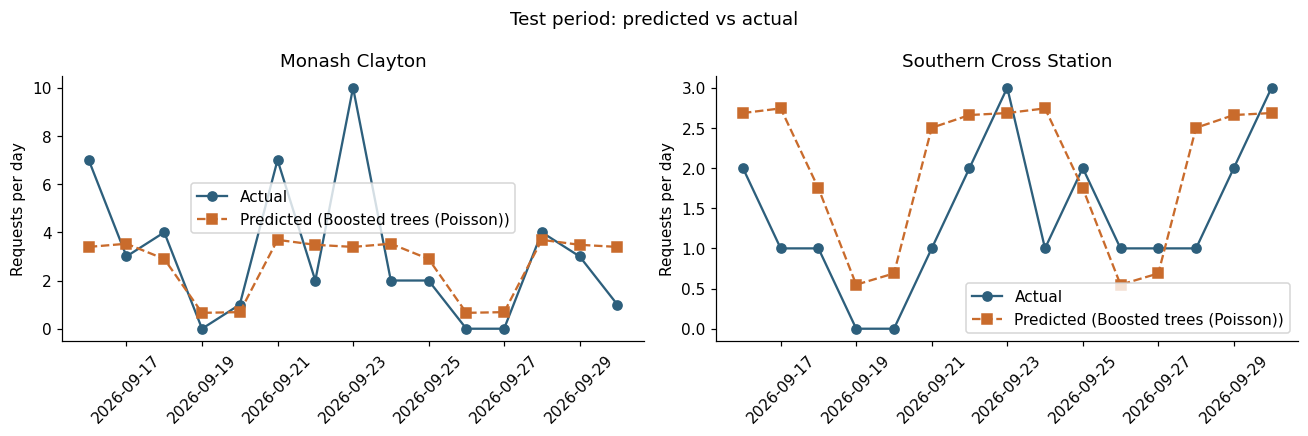

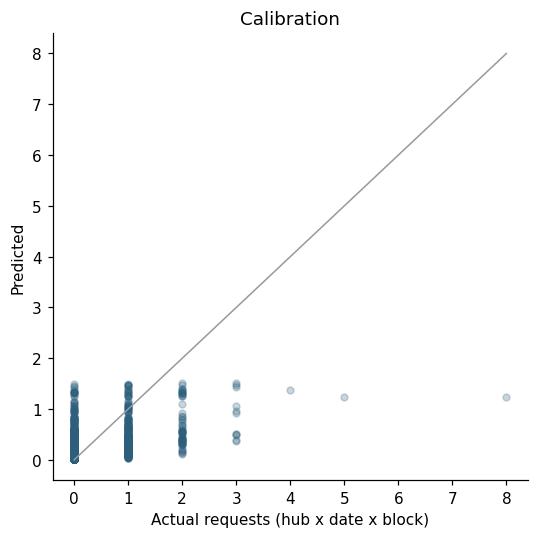

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
column = methods[best]
for ax, hub in zip(axes, ["Monash Clayton", "Southern Cross Station"]):
    daily_hub = test[test.hub == hub].groupby("date")[["requests", column]].sum()
    ax.plot(daily_hub.index, daily_hub.requests, "o-", label="Actual", color="#2d5f7c")
    ax.plot(daily_hub.index, daily_hub[column], "s--", label=f"Predicted ({best})", color="#c96b2c")
    ax.set_title(hub); ax.set_ylabel("Requests per day"); ax.tick_params(axis="x", rotation=45); ax.legend()
fig.suptitle("Test period: predicted vs actual"); fig.tight_layout(); fig.savefig(FIGURES / "predicted_vs_actual.png"); plt.show()

ax = block_level.plot.scatter("requests", column, alpha=0.25, figsize=(5, 5), color="#2d5f7c")
lim = block_level[["requests", column]].max().max(); ax.plot([0, lim], [0, lim], color="#999", lw=1)
ax.set_xlabel("Actual requests (hub x date x block)"); ax.set_ylabel("Predicted"); ax.set_title("Calibration")
plt.tight_layout(); plt.savefig(FIGURES / "calibration.png"); plt.show()

### What the Poisson model learned
Exponentiated coefficients are multipliers on the expected number of requests. The generator used Tue/Wed x1.1,
Mon/Thu x1.05 and Fri x0.8 (`SyntheticDemand.dayOfWeekFactor`) - a model that recovers those ratios has learned the real structure.

In [12]:
encoder = glm[0].named_transformers_["onehot"]
coefficients = pd.Series(glm[-1].coef_, index=encoder.get_feature_names_out(["hub", "role_slot", "day_of_week"]))
dow = np.exp(coefficients.filter(like="day_of_week_"))
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday_effects = (dow / dow["Fri"])[["Mon", "Tue", "Wed", "Thu", "Fri"]]
truth = pd.Series({"Mon": 1.05, "Tue": 1.1, "Wed": 1.1, "Thu": 1.05, "Fri": 0.8}) / 0.8
pd.DataFrame({"learned (vs Friday)": weekday_effects, "generator (vs Friday)": truth}).round(2)

,learned (vs Friday),generator (vs Friday)
Mon,1.40,1.31
Tue,1.40,1.38
Wed,1.38,1.38
Thu,1.60,1.31
Fri,1.00,1.00


## 8. Forecast for the app
Refit the best model on **all 75 days**, then predict a typical week: for every hub and each of the app's 8 time buckets
(weekday/weekend x morning/midday/afternoon/evening), the expected number of requests in that block on one day.
The app reads this file (`app/src/main/resources/demand_forecast.json`) through `ForecastDemandDataSource`.

In [13]:
final_model = glm if best == "Poisson regression" else gbt
final_design = design if best == "Poisson regression" else tree_design
final_model.fit(final_design(panel), panel.requests)

week = pd.MultiIndex.from_product([hubs.hub, range(1, 8), range(24)], names=["hub", "day_of_week", "hour"]).to_frame(index=False)
week["weekend"] = week.day_of_week >= 6
week = week.merge(hubs[["hub", "role", "cluster_factor"]], on="hub")
week["block"] = week.hour.map(block_of)
week["expected"] = final_model.predict(final_design(week))
per_day = week.groupby(["hub", "weekend", "block", "day_of_week"]).expected.sum()       # requests in that block on one day
forecast = per_day.groupby(["hub", "weekend", "block"]).mean().reset_index()            # averaged over weekdays / weekend days

payload = {
    "model": best,
    "target": "expected ride requests per hub in one time-of-day block on one day",
    "trainedOn": {"from": str(dates.min().date()), "to": str(dates.max().date()), "days": len(dates), "requests": int(panel.requests.sum())},
    "dataProvenance": "synthetic",
    "evaluation": {
        "testDays": int(test.date.nunique()),
        "poissonDeviance": round(float(hourly.loc[best, "Poisson deviance"]), 4),
        "baseline": best_baseline,
        "baselinePoissonDeviance": round(float(hourly.loc[best_baseline, "Poisson deviance"]), 4),
        "improvementOverBaseline": round(float(gain), 4),
        "top3HitRate": round(float(period_scores_table.loc[best, "Top-3 hubs correct"]), 4),
        "rankCorrelation": round(float(period_scores_table.loc[best, "Rank correlation"]), 4),
    },
    "forecasts": [
        {"hub": r.hub, "weekend": bool(r.weekend), "block": r.block, "expectedRequests": round(float(r.expected), 4)}
        for r in forecast.itertuples()
    ],
}
APP_FORECAST.parent.mkdir(parents=True, exist_ok=True)
APP_FORECAST.write_text(json.dumps(payload, indent=1, ensure_ascii=False) + "\n", encoding="utf-8")
print(f"Wrote {len(payload['forecasts'])} forecasts to {APP_FORECAST}")
forecast.pivot_table(index="hub", columns=["weekend", "block"], values="expected").round(2).sort_values((False, "MORNING"), ascending=False).head(10)

Wrote 240 forecasts to ..\app\src\main\resources\demand_forecast.json


weekend                                    False                         \
block                                  AFTERNOON EVENING MIDDAY MORNING   
hub                                                                       
Monash Clayton                              0.72    0.13   1.11    1.48   
Monash Melbourne City – 750 Collins St      0.37    0.04   0.63    0.63   
Monash Caulfield                            0.38    0.07   0.60    0.62   
Oakleigh Station                            1.18    0.53   0.54    0.49   
Clayton Station                             1.09    0.37   0.43    0.44   
Westall Station                             0.86    0.40   0.38    0.40   
Glen Waverley Station                       1.23    0.40   0.29    0.40   
Monash Parkville                            0.24    0.04   0.45    0.37   
Southern Cross Station                      1.12    0.38   0.46    0.34   
Caulfield Station                           0.82    0.43   0.46    0.34   

weekend                                    True                          
block                                  AFTERNOON EVENING MIDDAY MORNING  
hub                                                                      
Monash Clayton                              0.22    0.05   0.28    0.10  
Monash Melbourne City – 750 Collins St      0.13    0.02   0.21    0.04  
Monash Caulfield                            0.13    0.02   0.21    0.04  
Oakleigh Station                            0.27    0.12   0.35    0.08  
Clayton Station                             0.39    0.13   0.54    0.17  
Westall Station                             0.19    0.07   0.24    0.08  
Glen Waverley Station                       0.29    0.20   0.27    0.12  
Monash Parkville                            0.07    0.02   0.07    0.03  
Southern Cross Station                      0.23    0.06   0.35    0.06  
Caulfield Station                           0.29    0.08   0.41    0.10

## 9. Limitations
* **Synthetic history.** The model mostly recovers the rules that generated the data; with real requests the same
  pipeline applies (`docs/DEMAND.md`, *Replacing synthetic with real data*), but accuracy must be re-measured.
* **No external signals** - weather, exam weeks, public holidays and events are not modelled.
* **Point forecasts only.** A Poisson model implies a spread (variance = mean); the app does not show it yet.
* **Static forecast.** It is exported once; a live version would be retrained on a schedule by the backend.